# FIND THE FIGHT

This notebook demonstrates live fight detection, using a CNN-LSTM base model and pose estimation with Open Pose. Final part of this notebook shows live inference results from a webcam. Additionally, you can also upload a video file.

> **NOTE**: To use a webcam, you must run this Jupyter notebook on a computer with a webcam. If you run on a server, the webcam will not work. However, you can still do inference on a video in the final step.

## Imports

In [1]:
import collections
import sys
import time
from pathlib import Path

import cv2
import numpy as np
from IPython import display
from numpy.lib.stride_tricks import as_strided
from openvino.runtime import Core

from decoder import OpenPoseDecoder

sys.path.append("../utils")
import notebook_utils as utils

## The model

### Download the model

Use the `download_file`, a function from the `notebook_utils` file. It automatically creates a directory structure and downloads the selected model.

If you want to download another model, replace the name of the model and precision in the code below. 

> **NOTE**: This may require a different pose decoder.

In [62]:
# A directory where the model will be downloaded.
base_model_dir = Path("model")

# The name of the model from Open Model Zoo.
model_name = "human-pose-estimation-0001"
# Selected precision (FP32, FP16, FP16-INT8).
precision = "FP32"

model_path = base_model_dir / "intel" / model_name / precision / f"{model_name}.xml"

if not model_path.exists():
    model_url_dir = f"https://storage.openvinotoolkit.org/repositories/open_model_zoo/2022.1/models_bin/3/{model_name}/{precision}/"
    utils.download_file(model_url_dir + model_name + '.xml', model_path.name, model_path.parent)
    utils.download_file(model_url_dir + model_name + '.bin', model_path.with_suffix('.bin').name, model_path.parent)

In [63]:
model_path

WindowsPath('model/intel/human-pose-estimation-0001/FP32/human-pose-estimation-0001.xml')

### Load the model

Downloaded models are located in a fixed structure, which indicates a vendor, the name of the model and a precision.

Only a few lines of code are required to run the model. Read the network architecture and model weights from the `.bin` and `.xml` files to compile it for the desired device.

In [64]:
# Initialize OpenVINO Runtime
ie_core = Core()
# Read the network from a file.
model = ie_core.read_model(model_path)
# Let the AUTO device decide where to load the model (you can use CPU, GPU or MYRIAD as well).
compiled_model = ie_core.compile_model(model=model, device_name="AUTO", config={"PERFORMANCE_HINT": "LATENCY"})

# Get the input and output names of nodes.
input_layer = compiled_model.input(0)
output_layers = compiled_model.outputs

# Get the input size.
height, width = list(input_layer.shape)[2:]

Input layer has the name of the input node and output layers contain names of output nodes of the network. In the case of OpenPose Model, there is 1 input and 2 outputs: pafs and keypoints heatmap.

In [65]:
input_layer.any_name, [o.any_name for o in output_layers]

('data', ['Mconv7_stage2_L1', 'Mconv7_stage2_L2'])

## Processing

### OpenPoseDecoder

To transform the raw results from the neural network into pose estimations, you need Open Pose Decoder. It is provided in the [Open Model Zoo](https://github.com/openvinotoolkit/open_model_zoo/blob/master/demos/common/python/openvino/model_zoo/model_api/models/open_pose.py) and compatible with the `human-pose-estimation-0001` model.

If you choose a model other than `human-pose-estimation-0001` you will need another decoder (for example, AssociativeEmbeddingDecoder), which is available in the [demos section](https://github.com/openvinotoolkit/open_model_zoo/blob/master/demos/common/python/openvino/model_zoo/model_api/models/hpe_associative_embedding.py) of Open Model Zoo.

In [53]:
decoder = OpenPoseDecoder()

### Process Results

A bunch of useful functions to transform results into poses.

First, pool the heatmap. Since pooling is not available in numpy, use a simple method to do it directly with numpy. Then, use non-maximum suppression to get the keypoints from the heatmap. After that, decode poses by using the decoder. Since the input image is bigger than the network outputs, you need to multiply all pose coordinates by a scaling factor.

#### Get Centroid from skeleton by avering x and y coordinates

In [55]:
import math

def calculate_centroids_distances(centroids):
  # Calculate distances between centroids
  distances = []
  for i in range(len(centroids)):
    for j in range(len(centroids)):
      if i == j:
        continue
      centroid1 = centroids[i]["centroid"]
      centroid2 = centroids[j]["centroid"]
      human1 = centroids[i]["human_index"]
      human2 = centroids[j]["human_index"]
      x1, y1 = centroid1
      x2, y2 = centroid2
      distance = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2) # Calculating Euclidian Distance 
      distances.append(
        {"human_pair": (human1, human2), "distance": distance}
      )

  return distances, centroids
  # # Display or use the distance values
  # for distance in distances:
  #     print(str(distance))

def return_centroids(humans) -> list:
  centroids = []
  for index, keypoints in enumerate(humans):
    if len(keypoints) > 0:
      x_coordinates = keypoints[:, 0]
      y_coordinates = keypoints[:, 1]
      centroid_x = np.mean(x_coordinates)
      centroid_y = np.mean(y_coordinates)
      centroid = (centroid_x, centroid_y)
      centroids.append(
        {"human_index": index, "centroid": centroid}
      ) # { human_index: 1, centroid: (3,0) }

  return calculate_centroids_distances(centroids)

#### Functions for process the results

In [54]:
# 2D pooling in numpy (from: https://stackoverflow.com/a/54966908/1624463)
def pool2d(A, kernel_size, stride, padding, pool_mode="max"):
    """
    2D Pooling

    Parameters:
        A: input 2D array
        kernel_size: int, the size of the window
        stride: int, the stride of the window
        padding: int, implicit zero paddings on both sides of the input
        pool_mode: string, 'max' or 'avg'
    """
    # Padding
    A = np.pad(A, padding, mode="constant")

    # Window view of A
    output_shape = (
        (A.shape[0] - kernel_size) // stride + 1,
        (A.shape[1] - kernel_size) // stride + 1,
    )
    kernel_size = (kernel_size, kernel_size)
    A_w = as_strided(
        A,
        shape=output_shape + kernel_size,
        strides=(stride * A.strides[0], stride * A.strides[1]) + A.strides
    )
    A_w = A_w.reshape(-1, *kernel_size)

    # Return the result of pooling.
    if pool_mode == "max":
        return A_w.max(axis=(1, 2)).reshape(output_shape)
    elif pool_mode == "avg":
        return A_w.mean(axis=(1, 2)).reshape(output_shape)


# non maximum suppression
def heatmap_nms(heatmaps, pooled_heatmaps):
    return heatmaps * (heatmaps == pooled_heatmaps)


# Get poses from results.
def process_results2(img, pafs, heatmaps):
    # This processing comes from
    # https://github.com/openvinotoolkit/open_model_zoo/blob/master/demos/common/python/models/open_pose.py
    pooled_heatmaps = np.array(
        [[pool2d(h, kernel_size=3, stride=1, padding=1, pool_mode="max") for h in heatmaps[0]]]
    )
    nms_heatmaps = heatmap_nms(heatmaps, pooled_heatmaps)

    # Decode poses.
    poses, scores = decoder(heatmaps, nms_heatmaps, pafs)

    output_shape = list(compiled_model.output(index=0).partial_shape)
    output_scale = img.shape[1] / output_shape[3].get_length(), img.shape[0] / output_shape[2].get_length()
    print(output_scale)
    # Multiply coordinates by a scaling factor.
    poses[:, :, :2] *= output_scale
    return poses, scores

# Get poses from results.
def process_results(img, pafs, heatmaps):
    # This processing comes from
    # https://github.com/openvinotoolkit/open_model_zoo/blob/master/demos/common/python/models/open_pose.py
    pooled_heatmaps = np.array(
        [[pool2d(h, kernel_size=3, stride=1, padding=1, pool_mode="max") for h in heatmaps[0]]]
    )
    nms_heatmaps = heatmap_nms(heatmaps, pooled_heatmaps)

    # Decode poses.
    poses, scores = decoder(heatmaps, nms_heatmaps, pafs)
    distances, centroids = return_centroids(humans=poses)
    # (x == number of humans) | (y == coco keypoints) | (z == array of x, y and score of that keypoint)
    # Example of output: poses shape => (9, 17, 3) scores shape => (9,)
    # print(poses, scores)

    output_shape = list(compiled_model.output(index=0).partial_shape)
    output_scale = img.shape[1] / output_shape[3].get_length(), img.shape[0] / output_shape[2].get_length()
    # Multiply coordinates by a scaling factor.
    poses[:, :, :2] *= output_scale
    return poses, scores, distances, centroids

#### Process the distances with visualization

In [9]:
import csv
from glob import glob

non_violence_video_paths = glob("./datasets/fight-surv-dataset/nonViolence/*.mp4")
violence_video_paths = glob("./datasets/fight-surv-dataset/violence/*.mp4")

header = ["filename", "frame", "humans_detected", "human_pair", "distance"]

results_file = open('distances_results_fight_surv_dataset_v4_with_filters.csv', 'w', encoding='UTF8')
writer = csv.writer(results_file)

# write the header
writer.writerow(header)

all_videos = violence_video_paths

for video_file in all_videos:
  run_pose_estimation(writer, video_file, flip=False, use_popup=False, skip_first_frames=0)

# closing the file
results_file.close()

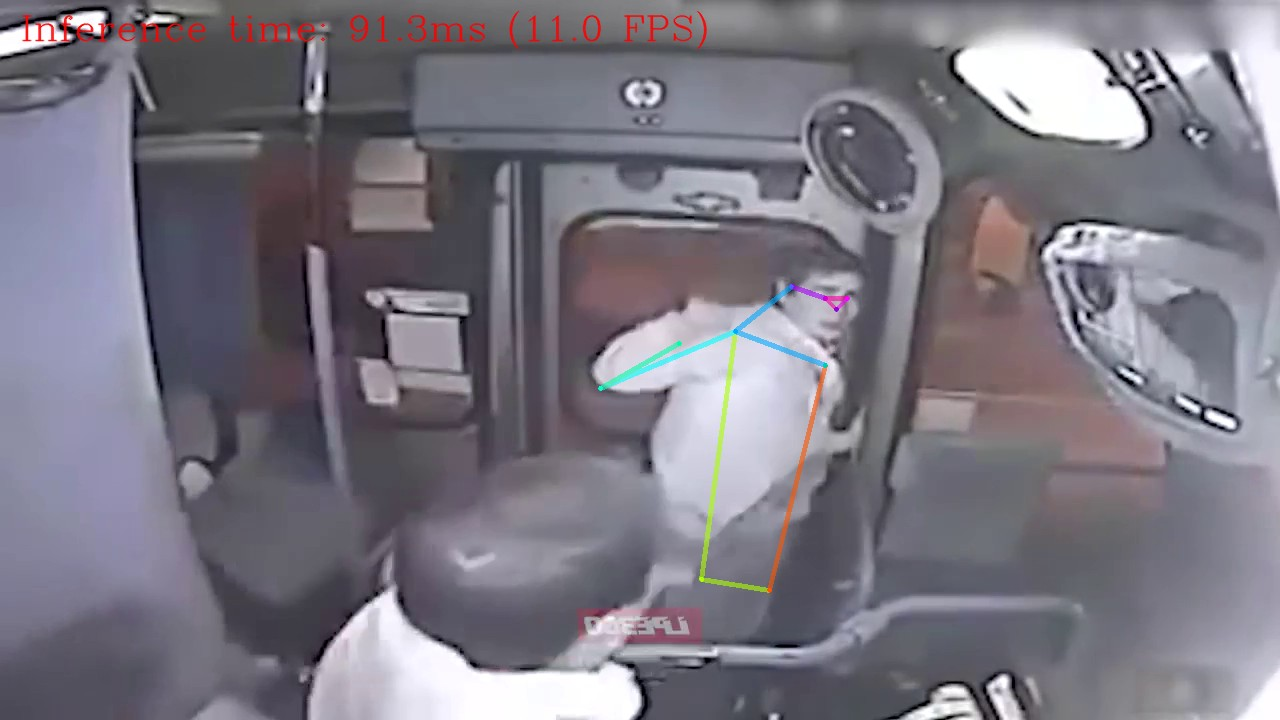

Source ended


In [108]:
# video_file = "https://github.com/mamonraab/Real-Time-Violence-Detection-in-Video-/blob/master/hospital.mp4?raw=true"
video_file = "https://github.com/seymanurakti/fight-detection-surv-dataset/blob/master/fight/fi149.mp4?raw=true"
# video_file = "https://github.com/intel-iot-devkit/sample-videos/blob/master/store-aisle-detection.mp4?raw=true"
run_pose_estimation(source=video_file, flip=True, use_popup=False, skip_first_frames=0)

In [9]:
from enum import Enum

class CocoPart(Enum):
  Nose = 0
  Neck = 1
  RShoulder = 2
  RElbow = 3
  RWrist = 4
  LShoulder = 5
  LElbow = 6
  LWrist = 7
  RHip = 8
  RKnee = 9
  RAnkle = 10
  LHip = 11
  LKnee = 12
  LAnkle = 13
  REye = 14
  LEye = 15
  REar = 16
  LEar = 17

CocoPairs = [
  (1, 2), (1, 5), (2, 3), (3, 4), (5, 6), (6, 7), (1, 8), (8, 9), (9, 10), (1, 11),
  (11, 12), (12, 13), (1, 0), (0, 14), (14, 16), (0, 15), (15, 17), (2, 16), (5, 17)
]   # = 19

def return_center_points(npimg, humans, imgcopy=False):
  image_h, image_w = npimg.shape[:2]
  centers = {}

  points=[]
  individuals=[]
  for counter in range(18):
      points.append((0,0))
  for human in humans:
    for i in range(CocoPart.Background.value - 1):
      body_part = human[i] # body_part[0] == x -- body_part[1] == y
      center = (int(body_part[0] * image_w + 0.5), int(body_part[1] * image_h + 0.5))
      centers[i] = center
      points[i] = center
    points_copy = points[:]
    individuals.append(points_copy)

  return individuals

In [56]:
import cv2
import numpy as np

def PM_anisotropic_diffusion(image, iterations, delta, kappa):
    # Convert the input image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Initialize the diffusion tensor
    D = np.ones(gray.shape, dtype=np.float32)

    for i in range(iterations):
        # Compute the gradient of the grayscale image
        grad = cv2.Sobel(gray, cv2.CV_32F, 1, 1)

        # Compute the magnitude and direction of the gradient
        mag = np.abs(grad)
        direction = np.sign(grad)

        # Compute the diffusion tensor
        Dxx = cv2.Sobel(D, cv2.CV_32F, 2, 0)
        Dyy = cv2.Sobel(D, cv2.CV_32F, 0, 2)
        Dxy = cv2.Sobel(D, cv2.CV_32F, 1, 1)
        D = (1 / (1 + ((mag * kappa) / delta)**2)) * \
            (D + delta**2 * (Dxx*direction[0]**2 + 2*Dxy*direction[0]*direction[1] + Dyy*direction[1]**2))

        # Apply the diffusion tensor to the image
        gray = gray + 0.25 * D * (cv2.Laplacian(gray, cv2.CV_32F))

    # Convert the output image back to color
    output = cv2.cvtColor(gray.astype(np.uint8), cv2.COLOR_GRAY2BGR)

    return output

def preprocess_frame_with_filters(image):
  blur_pm = PM_anisotropic_diffusion(image, 80, 0.20, 0.2)
  blur_pm_gray = cv2.cvtColor(blur_pm, cv2.COLOR_BGR2GRAY)
  # blur_pm_blur = cv2.GaussianBlur(blur_pm_gray, (5, 5), 0)
  # blur_pm_unsharp = cv2.addWeighted(blur_pm_gray, 2.15, blur_pm_blur, -1.1, 1)

  return cv2.cvtColor(blur_pm_gray.astype(np.uint8), cv2.COLOR_GRAY2BGR); # Convert the output image back to color

### Distances Average Calculation 

In [57]:
# Main processing function to run pose estimation.
def run_pose_estimation_with_distances_calculation(csv_results_writer = None, source=0, skip_first_frames=0, filters=False):
    pafs_output_key = compiled_model.output("Mconv7_stage2_L1")
    heatmaps_output_key = compiled_model.output("Mconv7_stage2_L2")
    player = None
    try:
        # Create a video player to play with target fps.
        player = utils.VideoPlayer(source, flip=False, fps=30, skip_first_frames=skip_first_frames)
        # Start capturing.
        player.start()

        processing_times = collections.deque()
        frame_counter = 0

        detected_skeletons = []
        video_processing_times = []
        all_average_distances = []

        while True:
            # Grab the frame.
            frame = player.next()
            if frame is None:
                # print("Source ended")
                break
            # If the frame is larger than full HD, reduce size to improve the performance.
            scale = 1280 / max(frame.shape)
            if scale < 1:
                frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

            # Resize the image and change dims to fit neural network input.
            # (see https://github.com/openvinotoolkit/open_model_zoo/tree/master/models/intel/human-pose-estimation-0001)
            input_img = cv2.resize(frame, (width, height), interpolation=cv2.INTER_AREA)


            # Create a batch of images (size = 1).
            input_img = input_img.transpose((2,0,1))[np.newaxis, ...]

            # Measure processing time.
            start_time = time.time()
            # Get results.
            results = compiled_model([input_img])
            stop_time = time.time()

            pafs = results[pafs_output_key]
            heatmaps = results[heatmaps_output_key]

            # applying preprocessig in the frames
            if filters:
              frame = preprocess_frame_with_filters(frame)

            # Get poses from network results.
            poses, scores, distances = process_results(frame, pafs, heatmaps)

            processing_times.append(stop_time - start_time)
            # Use processing times from last 200 frames.
            if len(processing_times) > 200:
                processing_times.popleft()

            _, f_width = frame.shape[:2]
            # mean processing time [ms]
            processing_time = np.mean(processing_times) * 1000

            detected_skeletons.append(len(poses))
            video_processing_times.append(processing_time)

            average_distance = 0.00
            if len(distances) > 0:
              for dist in distances:
                average_distance += dist["distance"]

              all_average_distances.append(average_distance / len(distances))

            frame_counter += 1

        average_distance_of_video = np.mean(all_average_distances)
        average_processing_time_of_video = np.mean(video_processing_times)
        average_detected_skeletons_of_video = np.mean(detected_skeletons)

        # HEADER: ["filename", "average_processing_time", "total_frames", "average_of_humans_detected", "average_distance"]
        # print(source, str(average_processing_time_of_video), str(frame_counter), str(average_detected_skeletons_of_video), str(round(average_distance_of_video, 3)))
        if csv_results_writer is not None:
          csv_results_writer.writerow([source, str(average_processing_time_of_video), str(frame_counter), str(average_detected_skeletons_of_video), average_distance_of_video])

        return average_distance_of_video
    # ctrl-c
    except KeyboardInterrupt:
        print("Interrupted")
    # any different error
    except RuntimeError as e:
        print(e)
    finally:
        if player is not None:
            # Stop capturing.
            player.stop()

#### Teste For Dataset: FIGHT DETECTION IN SURVEILLANCE VIDEOS DATASET

In [24]:
"""
  Code for Testing distances withiout filters
"""

results_file_without_filter = open('average_distances_results_fight_surv_dataset_v7_without_filters.csv', 'w', encoding='UTF8')
writer = csv.writer(results_file_without_filter)

header = ["filename", "average_processing_time", "total_frames", "average_of_humans_detected", "average_distance"]
# write the header
writer.writerow(header)

average_distances_results_fight_surv_dataset_without_filters = []

print("...processing")
for video_file in violence_video_paths:
  average_distance = run_pose_estimation_with_distances_calculation(csv_results_writer=writer, source=video_file, filters=False)
  average_distances_results_fight_surv_dataset_without_filters.append(average_distance)

# closing the file
results_file_without_filter.close()
clean_average_distances_results_fight_surv_dataset_without_filters = [dist for dist in average_distances_results_fight_surv_dataset_without_filters if str(dist) != 'nan']
print("FINISHED ----- WITHOUT FILTERS: fight_surv_dataset", round(np.mean(clean_average_distances_results_fight_surv_dataset_without_filters), 3))

...processing
FINISHED ----- WITHOUT FILTERS: fight_surv_dataset 11.579


E:\coding\graduation-project\openvino_env\lib\site-packages\numpy\core\fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
E:\coding\graduation-project\openvino_env\lib\site-packages\numpy\core\_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


#### Teste For Dataset: PELICULAS DATASET

In [56]:
import csv
from glob import glob

violence_video_paths = glob("./datasets/peliculas/violence/*.avi")

header = ["filename", "average_processing_time", "total_frames", "average_of_humans_detected", "average_distance"]

"""
  Code for Testing distances with filters
"""
results_file = open('average_distances_results_peliculas_v1_without_filters.csv', 'w', encoding='UTF8')
writer = csv.writer(results_file)

# write the header
writer.writerow(header)

average_distances_results_fight_surv_dataset_with_filters = []

for video_file in violence_video_paths:
  average_distance = run_pose_estimation_with_distances_calculation(csv_results_writer=writer, source=video_file, filters=False)
  average_distances_results_fight_surv_dataset_with_filters.append(average_distance)


# closing the file
results_file.close()

clean_average_distances_results_fight_surv_dataset_with_filters = [dist for dist in average_distances_results_fight_surv_dataset_with_filters if str(dist) != 'nan']
print("WITHOUT FILTERS: fight_surv_dataset", round(np.mean(clean_average_distances_results_fight_surv_dataset_with_filters), 3))

WITHOUT FILTERS: fight_surv_dataset 12.543


#####

#### Testes Real Life Situations Dataset

In [58]:
import csv
from glob import glob

violence_video_paths = glob("./datasets/real-life-situations-dataset/violence/*.mp4")

header = ["filename", "average_processing_time", "total_frames", "average_of_humans_detected", "average_distance"]

"""
  Code for Testing distances with filters
"""
results_file = open('average_distances_results_real_life_situations_dataset_v1_without_filters.csv', 'w', encoding='UTF8')
writer = csv.writer(results_file)

# write the header
writer.writerow(header)

average_distances_results_fight_surv_dataset_with_filters = []

for video_file in violence_video_paths:
  average_distance = run_pose_estimation_with_distances_calculation(csv_results_writer=writer, source=video_file, filters=False)
  average_distances_results_fight_surv_dataset_with_filters.append(average_distance)


# closing the file
results_file.close()

clean_average_distances_results_fight_surv_dataset_with_filters = [dist for dist in average_distances_results_fight_surv_dataset_with_filters if str(dist) != 'nan']
print("WITHOUT FILTERS: fight_surv_dataset", round(np.mean(clean_average_distances_results_fight_surv_dataset_with_filters), 3))

WITHOUT FILTERS: fight_surv_dataset 10.756


#### Tests Dataset For AIRTLab

In [59]:
import csv
from glob import glob

violence_video_paths = glob("./datasets/dataset-for-automatic-violence-detection-in-videos/violence/*.mp4")

header = ["filename", "average_processing_time", "total_frames", "average_of_humans_detected", "average_distance"]

"""
  Code for Testing distances with filters
"""
results_file = open('average_distances_results_dataset_for_automatic_violence_detection_in_videos_v1_without_filters.csv', 'w', encoding='UTF8')
writer = csv.writer(results_file)

# write the header
writer.writerow(header)

average_distances_results_fight_surv_dataset_with_filters = []

for video_file in violence_video_paths:
  average_distance = run_pose_estimation_with_distances_calculation(csv_results_writer=writer, source=video_file, filters=False)
  average_distances_results_fight_surv_dataset_with_filters.append(average_distance)


# closing the file
results_file.close()

clean_average_distances_results_fight_surv_dataset_with_filters = [dist for dist in average_distances_results_fight_surv_dataset_with_filters if str(dist) != 'nan']
print("WITHOUT FILTERS: dataset_for_automatic_violence_detection", round(np.mean(clean_average_distances_results_fight_surv_dataset_with_filters), 3))

WITHOUT FILTERS: dataset_for_automatic_violence_detection 13.898


#### Save 30 First Frames with Defined Threshold

In [13]:
import math

def calculate_centroids_distances_for_frame_extraction(centroids):
  # Calculate distances between centroids
  distances = []
  for i in range(len(centroids)):
    for j in range(len(centroids)):
      if i == j:
        continue
      centroid1 = centroids[i]
      centroid2 = centroids[j]
      x1, y1 = centroid1
      x2, y2 = centroid2
      distance = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2) # Calculating Euclidian Distance
      distances.append(distance)

  return distances

def return_centroids_for_frame_extraction(humans) -> list:
  centroids = []
  for index, keypoints in enumerate(humans):
    if len(keypoints) > 0:
      x_coordinates = keypoints[:, 0]
      y_coordinates = keypoints[:, 1]
      centroid_x = np.mean(x_coordinates)
      centroid_y = np.mean(y_coordinates)
      centroid = (centroid_x, centroid_y)
      centroids.append(centroid)

  return calculate_centroids_distances_for_frame_extraction(centroids)

# Get poses from results.
def process_results_for_frame_extraction(img, pafs, heatmaps):
  # This processing comes from
  # https://github.com/openvinotoolkit/open_model_zoo/blob/master/demos/common/python/models/open_pose.py
  pooled_heatmaps = np.array(
      [[pool2d(h, kernel_size=3, stride=1, padding=1, pool_mode="max") for h in heatmaps[0]]]
  )
  nms_heatmaps = heatmap_nms(heatmaps, pooled_heatmaps)

  # Decode poses.
  poses, scores = decoder(heatmaps, nms_heatmaps, pafs)
  distances = return_centroids_for_frame_extraction(humans=poses)
  # (x == number of humans) | (y == coco keypoints) | (z == array of x, y and score of that keypoint)
  # Example of output: poses shape => (9, 17, 3) scores shape => (9,)
  # print(poses, scores)

  output_shape = list(compiled_model.output(index=0).partial_shape)
  output_scale = img.shape[1] / output_shape[3].get_length(), img.shape[0] / output_shape[2].get_length()
  # Multiply coordinates by a scaling factor.
  poses[:, :, :2] *= output_scale
  return poses, scores, distances

In [14]:
### MAIN FUNCTION FOR PROCESS
# Main processing function to run pose estimation.
from copy import deepcopy

def load_video(source: str):
    cap = cv2.VideoCapture(source)
    video_frames = []

    try:
      while True:
        ret, frame = cap.read()

        if not ret:
          break

        # resize the frame for model input shape
        frame = cv2.resize(frame, (160,160), interpolation=cv2.INTER_AREA)

        # Picking the frame in RGB format
        # frame = frame[:, :, [2, 1, 0]]

        video_frames.append(frame)

        if len(video_frames) == 30:
          break
    finally:
        cap.release()

    return video_frames

def caputre_fifteen_first_frames(source):
  return load_video(source)

def pose_estimation_for_fight_frame_extraction_by_threshold(source=0, skip_first_frames=0, dist_threshold=12.0, use_distances_filter=True):
  pafs_output_key = compiled_model.output("Mconv7_stage2_L1")
  heatmaps_output_key = compiled_model.output("Mconv7_stage2_L2")
  player = None


  try:
    # Create a video player to play with target fps.
    player = utils.VideoPlayer(source, flip=False, fps=30, skip_first_frames=skip_first_frames)
    # Start capturing.
    player.start()

    processing_times = collections.deque()
    frame_counter = 0
    fight_frames = []

    while True:
      # Grab the frame.
      frame = player.next()
      original_frame = deepcopy(frame)

      if frame is None:
        break # ---> Source ended

      # If the frame is larger than full HD, reduce size to improve the performance.
      scale = 1280 / max(frame.shape)
      if scale < 1:
        frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

      # Resize the image and change dims to fit neural network input.
      # (see https://github.com/openvinotoolkit/open_model_zoo/tree/master/models/intel/human-pose-estimation-0001)
      input_img = cv2.resize(frame, (width, height), interpolation=cv2.INTER_AREA)

      # Create a batch of images (size = 1).
      input_img = input_img.transpose((2,0,1))[np.newaxis, ...]

      # Measure processing time.
      start_time = time.time()
      # Get results.
      results = compiled_model([input_img])
      stop_time = time.time()

      pafs = results[pafs_output_key]
      heatmaps = results[heatmaps_output_key]

      # Get poses from network results.
      poses, scores, distances = process_results_for_frame_extraction(frame, pafs, heatmaps)

      processing_times.append(stop_time - start_time)
      # Use processing times from last 200 frames.
      if len(processing_times) > 200:
        processing_times.popleft()

      # mean processing time [ms]
      processing_time = np.mean(processing_times) * 1000
      if use_distances_filter:
        if len(distances) > 0:
          np_distances = np.array(distances)

          # Using NumPy boolean indexing for verify if has some values in distance threshold
          np_distances = np_distances[np_distances <= dist_threshold]

          if np_distances.size > 0:
            frame_counter += 1
            # Resize the image and change dims to fit fioght detection neural network input.
            _fight_frame = cv2.resize(original_frame, (160, 160), interpolation=cv2.INTER_AREA)
            fight_frames.append(_fight_frame)

      if len(fight_frames) == 30:
        break

    if not (len(fight_frames) == 30):
      # If you don't have the 10 frames with the distances between the trashold defined, the first 10 frames are taken
      ## to avoid leaving an empty folder due to the error of the pose estimation network
      fight_frames = caputre_fifteen_first_frames(source)

    return fight_frames
  # ctrl-c
  except KeyboardInterrupt:
    print("Interrupted")
  # any different error
  except RuntimeError as e:
    print(e)
  finally:
    if player is not None:
      # Stop capturing.
      player.stop()

#### Fight Surveillance Dataset

In [15]:
import os
from glob import glob

In [38]:
import os
from glob import glob

violence_video_paths = glob("C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\fight-detection-surv-dataset\\non-violence\\*.mp4")

for video_path in violence_video_paths:
  fight_frames = pose_estimation_for_fight_frame_extraction_by_threshold(source=video_path, dist_threshold=12.0, use_distances_filter=False)
  images_folder_name = video_path.split("\\non-violence\\")[1].split(".mp4")[0]
  base_dataset_dir = "C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\fight-detection-surv-dataset\\video_images\\non-violence"
  images_folder_path = os.path.join(base_dataset_dir, f"{images_folder_name}")
  if not os.path.exists(images_folder_path):
    os.makedirs(images_folder_path)

  # print(images_folder_name, len(fight_frames))
  if len(fight_frames) == 30:
    for index, frame in enumerate(fight_frames):
      img_path = os.path.join(images_folder_path, f"{images_folder_name}_non_violence_{index}.png")
      cv2.imwrite(img_path, frame)

print("...finished")

...finished


In [39]:
import os

violence_video_paths = glob("C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\fight-detection-surv-dataset\\violence\\*.mp4")

for video_path in violence_video_paths:
  fight_frames = pose_estimation_for_fight_frame_extraction_by_threshold(source=video_path, dist_threshold=12.0)
  images_folder_name = video_path.split("\\violence\\")[1].split(".mp4")[0]
  base_dataset_dir = "C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\fight-detection-surv-dataset\\video_images\\violence"
  images_folder_path = os.path.join(base_dataset_dir, f"{images_folder_name}")
  if not os.path.exists(images_folder_path):
    os.makedirs(images_folder_path)


  if len(fight_frames) == 30:
    for index, frame in enumerate(fight_frames):
      img_path = os.path.join(images_folder_path, f"{images_folder_name}_violence_{index}.png")
      cv2.imwrite(img_path, frame)

print("...finished")

...finished


#### Peliculas Dataset

In [16]:
import os

violence_video_paths = glob("C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\peliculas\\non-violence\\*.mpg")

for video_path in violence_video_paths:
  fight_frames = pose_estimation_for_fight_frame_extraction_by_threshold(source=video_path, dist_threshold=13.0, use_distances_filter=False)
  images_folder_name = video_path.split("\\non-violence\\")[1].split(".mpg")[0]
  base_dataset_dir = "C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\peliculas\\video_images\\non-violence"
  images_folder_path = os.path.join(base_dataset_dir, f"{images_folder_name}")
  if not os.path.exists(images_folder_path):
    os.makedirs(images_folder_path)


  if len(fight_frames) == 30:
    for index, frame in enumerate(fight_frames):
      img_path = os.path.join(images_folder_path, f"{images_folder_name}_non_violence_{index}.png")
      cv2.imwrite(img_path, frame)

print("...finished")

...finished


In [17]:
import os

violence_video_paths = glob("C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\peliculas\\violence\\*.avi")

for video_path in violence_video_paths:
  fight_frames = pose_estimation_for_fight_frame_extraction_by_threshold(source=video_path, dist_threshold=13.0)
  images_folder_name = video_path.split("\\violence\\")[1].split(".avi")[0]
  base_dataset_dir = "C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\peliculas\\video_images\\violence"
  images_folder_path = os.path.join(base_dataset_dir, f"{images_folder_name}")
  if not os.path.exists(images_folder_path):
    os.makedirs(images_folder_path)

  # print(images_folder_name, len(fight_frames))
  if len(fight_frames) == 30:
    for index, frame in enumerate(fight_frames):
      img_path = os.path.join(images_folder_path, f"{images_folder_name}_violence_{index}.png")
      cv2.imwrite(img_path, frame)

print("...finished")

...finished


#### Real Life Situations Dataset

In [18]:
import os

violence_video_paths = glob("C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\real-life-situations-dataset\\non-violence\\*.mp4")
for video_path in violence_video_paths:
  fight_frames = pose_estimation_for_fight_frame_extraction_by_threshold(source=video_path, dist_threshold=11.0, use_distances_filter=False)
  images_folder_name = video_path.split("\\non-violence\\")[1].split(".mp4")[0]
  base_dataset_dir = "C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\real-life-situations-dataset\\video_images\\non-violence"
  images_folder_path = os.path.join(base_dataset_dir, f"{images_folder_name}")
  if not os.path.exists(images_folder_path):
    os.makedirs(images_folder_path)

  # print(images_folder_name, len(fight_frames))
  if len(fight_frames) == 30:
    for index, frame in enumerate(fight_frames):
      img_path = os.path.join(images_folder_path, f"{images_folder_name}_non_violence_{index}.png")
      cv2.imwrite(img_path, frame)

print("...finished")

...finished


In [19]:
import os

violence_video_paths = glob("C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\real-life-situations-dataset\\violence\\*.mp4")
for video_path in violence_video_paths:
  fight_frames = pose_estimation_for_fight_frame_extraction_by_threshold(source=video_path, dist_threshold=11.0)
  images_folder_name = video_path.split("\\violence\\")[1].split(".mp4")[0]
  base_dataset_dir = "C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\real-life-situations-dataset\\video_images\\violence"
  images_folder_path = os.path.join(base_dataset_dir, f"{images_folder_name}")
  if not os.path.exists(images_folder_path):
    os.makedirs(images_folder_path)
    print("Directory created:", images_folder_path)
  # print(images_folder_name, len(fight_frames))
  if len(fight_frames) == 30:
    for index, frame in enumerate(fight_frames):
      img_path = os.path.join(images_folder_path, f"{images_folder_name}_violence_{index}.png")
      cv2.imwrite(img_path, frame)

print("...finished")

...finished


#### Dataset For Automatic Violence Detection in Videos

In [20]:
import os

violence_video_paths = glob("C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\dataset-for-automatic-violence-detection-in-videos\\violence\\*.mp4")
for video_path in violence_video_paths:
  fight_frames = pose_estimation_for_fight_frame_extraction_by_threshold(source=video_path, dist_threshold=14.0)
  images_folder_name = video_path.split("\\violence\\")[1].split(".mp4")[0]
  base_dataset_dir = "C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\dataset-for-automatic-violence-detection-in-videos\\video_images\\violence"
  images_folder_path = os.path.join(base_dataset_dir, f"{images_folder_name}")
  if not os.path.exists(images_folder_path):
    os.makedirs(images_folder_path)

  # print(images_folder_name, len(fight_frames))
  if len(fight_frames) == 30:
    for index, frame in enumerate(fight_frames):
      img_path = os.path.join(images_folder_path, f"{images_folder_name}_violence_{index}.png")
      cv2.imwrite(img_path, frame)

print("...finished")

...finished


In [21]:
import os

violence_video_paths = glob("C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\dataset-for-automatic-violence-detection-in-videos\\non-violence\\*.mp4")
for video_path in violence_video_paths:
  fight_frames = pose_estimation_for_fight_frame_extraction_by_threshold(source=video_path, dist_threshold=14.0, use_distances_filter=False)
  images_folder_name = video_path.split("\\non-violence\\")[1].split(".mp4")[0]
  base_dataset_dir = "C:\\coding\\graduation-project\\openvino_notebooks\\notebooks\\402-pose-estimation-webcam\\datasets\\dataset-for-automatic-violence-detection-in-videos\\video_images\\non-violence"
  images_folder_path = os.path.join(base_dataset_dir, f"{images_folder_name}")
  if not os.path.exists(images_folder_path):
    os.makedirs(images_folder_path)

  # print(images_folder_name, len(fight_frames))
  if len(fight_frames) == 30:
    for index, frame in enumerate(fight_frames):
      img_path = os.path.join(images_folder_path, f"{images_folder_name}_non_violence_{index}.png")
      cv2.imwrite(img_path, frame)

print("...finished")

...finished


### Draw Pose Overlays

Draw pose overlays on the image to visualize estimated poses. Joints are drawn as circles and limbs are drawn as lines. The code is based on the [Human Pose Estimation Demo](https://github.com/openvinotoolkit/open_model_zoo/tree/master/demos/human_pose_estimation_demo/python) from Open Model Zoo.

In [58]:
colors = ((255, 0, 0), (255, 0, 255), (170, 0, 255), (255, 0, 85), (255, 0, 170), (85, 255, 0),
          (255, 170, 0), (0, 255, 0), (255, 255, 0), (0, 255, 85), (170, 255, 0), (0, 85, 255),
          (0, 255, 170), (0, 0, 255), (0, 255, 255), (85, 0, 255), (0, 170, 255))

default_skeleton = ((15, 13), (13, 11), (16, 14), (14, 12), (11, 12), (5, 11), (6, 12), (5, 6), (5, 7),
                    (6, 8), (7, 9), (8, 10), (1, 2), (0, 1), (0, 2), (1, 3), (2, 4), (3, 5), (4, 6))

# usar isso aqui para conseguir pegar os pontos x e y e calcular as distâncias do centroid
def draw_poses(img, poses, point_score_threshold, skeleton=default_skeleton):
    if poses.size == 0:
        return img

    img_limbs = np.copy(img)
    for pose in poses:
        points = pose[:, :2].astype(np.int32)
        points_scores = pose[:, 2]
        # Draw joints.
        for i, (p, v) in enumerate(zip(points, points_scores)):
            if v > point_score_threshold:
                cv2.circle(img, tuple(p), 1, colors[i], 2)
                # print(p)
        # Draw limbs.
        for i, j in skeleton:
            if points_scores[i] > point_score_threshold and points_scores[j] > point_score_threshold:
                cv2.line(img_limbs, tuple(points[i]), tuple(points[j]), color=colors[j], thickness=4)
    cv2.addWeighted(img, 0.4, img_limbs, 0.6, 0, dst=img)
    return img

In [60]:
# Main processing function to run pose estimation.
def run_pose_estimation(source=0, flip=False, use_popup=False, skip_first_frames=0):
    pafs_output_key = compiled_model.output("Mconv7_stage2_L1")
    heatmaps_output_key = compiled_model.output("Mconv7_stage2_L2")
    player = None
    try:
        # Create a video player to play with target fps.
        player = utils.VideoPlayer(source, flip=flip, fps=30, skip_first_frames=skip_first_frames)
        # Start capturing.
        player.start()
        if use_popup:
            title = "Press ESC to Exit"
            cv2.namedWindow(title, cv2.WINDOW_GUI_NORMAL | cv2.WINDOW_AUTOSIZE)

        # out_video_writer = cv2.VideoWriter('example-inference.mp4',cv2.VideoWriter_fourcc(*"mp4v"), 15, (299,299))

        processing_times = collections.deque()
        frame_counter = 0
        while True:
            # Grab the frame.
            frame = player.next()
            if frame is None:
                print("Source ended")
                break
            # If the frame is larger than full HD, reduce size to improve the performance.
            scale = 1280 / max(frame.shape)
            if scale < 1:
                frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

            # Resize the image and change dims to fit neural network input.
            # (see https://github.com/openvinotoolkit/open_model_zoo/tree/master/models/intel/human-pose-estimation-0001)
            input_img = cv2.resize(frame, (width, height), interpolation=cv2.INTER_AREA)

            # Create a batch of images (size = 1).
            input_img = input_img.transpose((2,0,1))[np.newaxis, ...]

            # Measure processing time.
            start_time = time.time()
            # Get results.
            results = compiled_model([input_img])
            stop_time = time.time()

            pafs = results[pafs_output_key]
            heatmaps = results[heatmaps_output_key]
            # Get poses from network results.
            # print(f"\n>>Frame Number [{frame_counter}]\n")
            # frame = preprocess_frame_with_filters(frame)
            poses, scores, distances, centroides = process_results(frame, pafs, heatmaps)
            # Draw poses on a frame.
            frame = draw_poses(frame, poses, 0.1)

            # for i in range(len(centroides)):
            #   # print(tuple(map(int, centroides[i]["centroid"])))
            #   points = tuple(value * 10 for value in tuple(map(int, centroides[i]["centroid"])))
            #   cv2.circle(frame, points, 2, (127,0,255), 2)

            processing_times.append(stop_time - start_time)
            # Use processing times from last 200 frames.
            if len(processing_times) > 200:
                processing_times.popleft()

            _, f_width = frame.shape[:2]
            # mean processing time [ms]
            processing_time = np.mean(processing_times) * 1000
            fps = 1000 / processing_time
            average_dist = 0.0
            if len(distances) > 0:
                average_dist = np.mean([dist["distance"] for dist in distances])
            # Average Dist: {round(average_dist, 2)}px
            cv2.putText(frame, f"Inference time: {processing_time:.1f}ms ({fps:.1f} FPS)", (20, 40),
                        cv2.FONT_HERSHEY_COMPLEX, f_width / 1100, (0, 0, 255), 1, cv2.LINE_AA)



            frame_counter += 1
            # Use this workaround if there is flickering.
            # cv2.imwrite(f"results/images/frame-{frame_counter}.png", frame)

            if use_popup:
                cv2.imshow(title, frame)
                key = cv2.waitKey(1)
                # escape = 27
                if key == 27:
                    break
            else:
                # Encode numpy array to jpg.
                _, encoded_img = cv2.imencode(".jpg", frame, params=[cv2.IMWRITE_JPEG_QUALITY, 90])
                # Create an IPython image.
                i = display.Image(data=encoded_img)
                # Display the image in this notebook.
                display.clear_output(wait=True)
                display.display(i)
    # ctrl-c
    except KeyboardInterrupt:
        print("Interrupted")
    # any different error
    except RuntimeError as e:
        print(e)
    finally:
        if player is not None:
            # Stop capturing.
            player.stop()
        if use_popup:
            cv2.destroyAllWindows()

## Model to Violence Detection

In [94]:
from skimage.transform import resize
from tensorflow.keras.applications.vgg19 import VGG19
from tensorflow.keras.layers import Flatten, TimeDistributed, LSTM, Dense, GlobalAveragePooling1D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential
from skimage.io import imread
from skimage.transform import resize
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

### Utils to prediction

In [100]:
def create_fight_predictor(weight_path='bestsavedweights.hdfs'):
  num_classes = 2
  np.random.seed(1234)

  cnn = Sequential()

  base_model = VGG19(include_top=False,weights='imagenet',input_shape=(160, 160,3))

  cnn = Sequential()
  cnn.add(base_model)
  cnn.add(Flatten())
  model = Sequential()

  model.add(TimeDistributed(cnn,  input_shape=(30, 160, 160, 3)))
  model.add(LSTM(30 , return_sequences= True))

  model.add(TimeDistributed(Dense(90)))
  model.add(Dropout(0.1))

  model.add(GlobalAveragePooling1D())

  model.add(Dense(512, activation='relu'))
  model.add(Dropout(0.3))

  model.add(Dense(num_classes, activation="sigmoid"))

  adam = Adam(learning_rate=0.0005, beta_1=0.9, beta_2=0.999, epsilon=1e-08)
  model.load_weights(weight_path)

  model.compile(loss='binary_crossentropy', optimizer=adam, metrics=["accuracy"])

  return model

In [101]:
def create_RealLifeSituations_fight_predictor(weight='REAL-LIFE-SITUATIONS-WEIGHTS.h5'):
  np.random.seed(1234)
  num_classes = 2

  base_model = VGG19(include_top=False,weights='imagenet',input_shape=(160, 160,3))

  cnn = Sequential()
  # Add base pre treined model
  cnn.add(base_model)

  # Add flatten layer
  cnn.add(Flatten())

  # define LSTM model
  model = Sequential()

  model.add(TimeDistributed(cnn,  input_shape=(30, 160, 160, 3)))
  model.add(LSTM(40 , return_sequences=True))

  model.add(TimeDistributed(Dense(160, activation='relu')))

  model.add(GlobalAveragePooling1D(name="globale"))

  model.add(Dense(num_classes, activation="sigmoid" , name="last"))

  adam = Adam(learning_rate=0.0005, beta_1=0.9, beta_2=0.999, epsilon=1e-08)

  model.load_weights(weight)

  model.compile(loss='binary_crossentropy', optimizer=adam, metrics=["accuracy"])

  return model

In [ ]:
def create_AIRTLab_fight_predictor(weight='AIRTLabWeights30Frames.h5'):
  np.random.seed(1234)
  num_classes = 2

  base_model = VGG19(include_top=False,weights='imagenet',input_shape=(160, 160,3))

  cnn = Sequential()
  # Add base pre treined model
  cnn.add(base_model)

  # Add flatten layer
  cnn.add(Flatten())

  # define LSTM model
  model = Sequential()

  model.add(TimeDistributed(cnn,  input_shape=(30, 160, 160, 3)))
  model.add(LSTM(40 , return_sequences=True))

  model.add(TimeDistributed(Dense(160, activation='relu')))

  model.add(GlobalAveragePooling1D(name="globale"))

  model.add(Dense(num_classes, activation="sigmoid" , name="last"))

  adam = Adam(learning_rate=0.0005, beta_1=0.9, beta_2=0.999, epsilon=1e-08)

  model.load_weights(weight)

  model.compile(loss='binary_crossentropy', optimizer=adam, metrics=["accuracy"])

  return model

In [92]:
def pred_fight(fight_model, video,acuracy=0.9):
    pred_test = fight_model.predict(video, verbose=0)
    if pred_test[0][1] >= acuracy:
        return True , pred_test[0][1]
    else:
        return False , pred_test[0][1]

### Run Prediction and Saving Locale Video

In [102]:
fight_model = create_fight_predictor()

In [109]:
# cap = cv2.VideoCapture('Bar-fight-caught-on-camera-yt-crop.mp4')
# cap = cv2.VideoCapture('fi115.mp4')
cap = cv2.VideoCapture('crowdfight-news.mp4')
i = 0
frames = np.zeros((30, 160, 160, 3), dtype=float)
old = []
j = 0
while(True):
    ret, frame = cap.read()
    if not ret:
      break
    # describe the type of font
    # to be used.
    font = cv2.FONT_HERSHEY_DUPLEX
    if i > 29:
        ysdatav2 = np.zeros((1, 30, 160, 160, 3), dtype=float)
        ysdatav2[0][:][:] = frames
        predaction = pred_fight(fight_model, ysdatav2, acuracy=0.96)
        if predaction[0] == True:
            cv2.putText(frame, 'Violance Deacted...', (50, 50), font, 3, (0, 255, 255), 2, cv2.LINE_4)
            cv2.imshow('video', frame)
            print('Violance detected here ...')
            fourcc = cv2.VideoWriter_fourcc(*'XVID')
            video_writer = cv2.VideoWriter("./videos/output-"+str(j)+".avi", fourcc, 10.0, (frame_width, frame_height))
            for frameinss in old:
              video_writer.write(frameinss)

            video_writer.release()
        i = 0
        j += 1
        frames = np.zeros((30, 160, 160, 3), dtype=float)
        old = []
    else:
        frm = resize(frame, (160,160,3))
        old.append(frame)
        frame_shape = frame.shape if frame is not None else np.array([160,160])
        frame_height = frame_shape[0]
        frame_width = frame_shape[1]
        frm = np.expand_dims(frm, axis=0)
        if np.max(frm) > 1:
            frm = frm / 255.0
        frames[i][:] = frm

        i+=1

    cv2.imshow('video', frame)


    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()

cv2.destroyAllWindows()

In [ ]:
# Main processing function to violence detection.
def run_inference(source=0, flip=False, use_popup=False, skip_first_frames=0):
    pafs_output_key = compiled_model.output("Mconv7_stage2_L1")
    heatmaps_output_key = compiled_model.output("Mconv7_stage2_L2")
    player = None
    try:
        # Create a video player to play with target fps.
        player = utils.VideoPlayer(source, flip=flip, fps=30, skip_first_frames=skip_first_frames)

        # Start capturing.
        player.start()
        if use_popup:
            title = "Press ESC to Exit"
            cv2.namedWindow(title, cv2.WINDOW_GUI_NORMAL | cv2.WINDOW_AUTOSIZE)

        processing_times = collections.deque()
        frame_counter = 0
        while True:
            # Grab the frame.
            frame = player.next()
            if frame is None:
                print("Source ended")
                break

            # If the frame is larger than full HD, reduce size to improve the performance.
            scale = 1280 / max(frame.shape)
            if scale < 1:
                frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

            # Resize the image and change dims to fit neural network input.
            # (see https://github.com/openvinotoolkit/open_model_zoo/tree/master/models/intel/human-pose-estimation-0001)
            input_img = cv2.resize(frame, (width, height), interpolation=cv2.INTER_AREA)

            # Create a batch of images (size = 1).
            input_img = input_img.transpose((2,0,1))[np.newaxis, ...]

            # Measure processing time.
            start_time = time.time()
            # Get results.
            results = compiled_model([input_img])
            stop_time = time.time()

            pafs = results[pafs_output_key]
            heatmaps = results[heatmaps_output_key]
            # Get poses from network results.
            # print(f"\n>>Frame Number [{frame_counter}]\n")
            # frame = preprocess_frame_with_filters(frame)
            poses, scores, distances, centroides = process_results(frame, pafs, heatmaps)
            # Draw poses on a frame.
            frame = draw_poses(frame, poses, 0.1)

            # for i in range(len(centroides)):
            #   # print(tuple(map(int, centroides[i]["centroid"])))
            #   points = tuple(value * 10 for value in tuple(map(int, centroides[i]["centroid"])))
            #   cv2.circle(frame, points, 2, (127,0,255), 2)

            processing_times.append(stop_time - start_time)
            # Use processing times from last 200 frames.
            if len(processing_times) > 200:
                processing_times.popleft()

            _, f_width = frame.shape[:2]
            # mean processing time [ms]
            processing_time = np.mean(processing_times) * 1000
            fps = 1000 / processing_time
            average_dist = 0.0
            if len(distances) > 0:
                average_dist = np.mean([dist["distance"] for dist in distances])
            # Average Dist: {round(average_dist, 2)}px
            cv2.putText(frame, f"Inference time: {processing_time:.1f}ms ({fps:.1f} FPS)", (20, 40),
                        cv2.FONT_HERSHEY_COMPLEX, f_width / 1100, (0, 0, 255), 1, cv2.LINE_AA)



            frame_counter += 1
            # Use this workaround if there is flickering.
            # cv2.imwrite(f"results/images/frame-{frame_counter}.png", frame)

            if use_popup:
                cv2.imshow(title, frame)
                key = cv2.waitKey(1)
                # escape = 27
                if key == 27:
                    break
            else:
                # Encode numpy array to jpg.
                _, encoded_img = cv2.imencode(".jpg", frame, params=[cv2.IMWRITE_JPEG_QUALITY, 90])
                # Create an IPython image.
                i = display.Image(data=encoded_img)
                # Display the image in this notebook.
                display.clear_output(wait=True)
                display.display(i)
    # ctrl-c
    except KeyboardInterrupt:
        print("Interrupted")
    # any different error
    except RuntimeError as e:
        print(e)
    finally:
        if player is not None:
            # Stop capturing.
            player.stop()
        if use_popup:
            cv2.destroyAllWindows()

## Run

### Run Live Pose Estimation

Use a webcam as the video input. By default, the primary webcam is set with `source=0`. If you have multiple webcams, each one will be assigned a consecutive number starting at 0. Set `flip=True` when using a front-facing camera. Some web browsers, especially Mozilla Firefox, may cause flickering. If you experience flickering, set `use_popup=True`.

> **NOTE**: To use this notebook with a webcam, you need to run the notebook on a computer with a webcam. If you run the notebook on a server (for example, Binder), the webcam will not work. Popup mode may not work if you run this notebook on a remote computer (for example, Binder).

Run the pose estimation:

In [ ]:
run_pose_estimation(source=0, flip=True, use_popup=False)

### Run Pose Estimation on a Video File

If you do not have a webcam, you can still run this demo with a video file. Any [format supported by OpenCV](https://docs.opencv.org/4.5.1/dd/d43/tutorial_py_video_display.html) will work. You can skip first `N` frames to fast forward video.

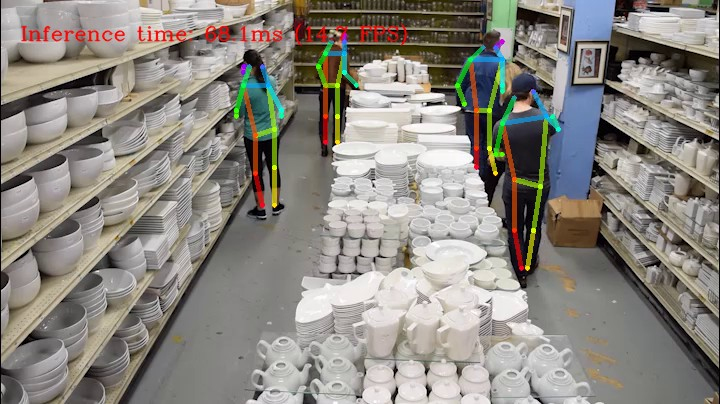

Source ended


In [68]:
video_file = "https://github.com/seymanurakti/fight-detection-surv-dataset/blob/master/fight/fi110.mp4?raw=true"
video_file = "https://github.com/mamonraab/Real-Time-Violence-Detection-in-Video-/blob/master/hospital.mp4?raw=true"
video_file = "https://github.com/intel-iot-devkit/sample-videos/blob/master/store-aisle-detection.mp4?raw=true"
frames = run_pose_estimation(video_file, flip=True, use_popup=False, skip_first_frames=550)


In [69]:
np.array(frames)


array(None, dtype=object)

In [59]:
largura = 360
altura = 640
fps = 15
codec = cv2.VideoWriter_fourcc(*"mp4v")
nome_arquivo_saida = 'openpose-inference.mp4'
video_saida = cv2.VideoWriter(nome_arquivo_saida, codec, fps, (largura, altura))
for frame in frames:
  frame_cv2 = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
  video_saida.write(frame_cv2)  # Salva o frame no vídeo de saída

video_saida.release()  # Fecha o arquivo de vídeo de saída


: 